In [1]:
from google.colab import files

# Prompt to upload kaggle.json from your computer
uploaded = files.upload()

Saving kaggle.json to kaggle.json


In [2]:
import os
import zipfile

# 1. Create hidden Kaggle directory and move credentials
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

# 2. Download the Cocoa Disease Unified Dataset
!kaggle datasets download -d danielohachor/cocoa-disease-unified

# 3. Extract the downloaded zip archive
zip_path = "cocoa-disease-unified.zip"
extract_dir = "./cocoa_unified_dataset"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_dir)

print("Dataset extracted successfully.")

Dataset URL: https://www.kaggle.com/datasets/danielohachor/cocoa-disease-unified
License(s): other
100% 5.08G/5.08G [01:00<00:00, 89.7MB/s]

Dataset extracted successfully.


### 1. Environment & GPU Verification

In [3]:
import sys
import torch

print(f"Python Version: {sys.version}")
print(f"PyTorch Version: {torch.__version__}")

gpu_available = torch.cuda.is_available()
print(f"GPU Available: {gpu_available}")
if gpu_available:
    print(f"GPU Device Name: {torch.cuda.get_device_name(0)}")

Python Version: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
PyTorch Version: 2.11.0+cu130
GPU Available: True
GPU Device Name: Tesla T4


### 2. Dataset Structure Inspection
We will recursively traverse the extracted dataset directory to look for directories, image files, annotation formats, and nested structures without printing an excessively long output.

In [4]:
import os
from pathlib import Path

base_path = Path('./cocoa_unified_dataset')

def print_directory_tree(path, max_depth=3, current_depth=0):
    if current_depth > max_depth:
        return

    indent = "  " * current_depth
    try:
        items = list(path.iterdir())
    except OSError:
        return

    # Separate dirs and files
    dirs = [d for d in items if d.is_dir()]
    files = [f for f in items if f.is_file()]

    for d in sorted(dirs):
        print(f"{indent}📁 {d.name}/")
        print_directory_tree(d, max_depth, current_depth + 1)

    # Limit displayed files to avoid clutter
    if files:
        limit = 3
        for f in sorted(files)[:limit]:
            print(f"{indent}📄 {f.name}")
        if len(files) > limit:
            print(f"{indent}📄 ... and {len(files) - limit} more files")

print_directory_tree(base_path)

📁 anthracnose/
  📄 ID_A5PBJ2_9501.jpg
  📄 ID_A9j4mt_2742.jpg
  📄 ID_A9j4mt_2743.jpg
  📄 ... and 2261 more files
📁 black_pod_rot/
  📄 bryan_07edaecf-887c-4b92-8f97-9b6fade1ffc3_0.jpg
  📄 bryan_086e0826-c887-484d-a38a-c1740d35afcd_0.jpg
  📄 bryan_0a4a2fe1-c683-4626-b2c8-8111ec3a3613_0.jpg
  📄 ... and 3219 more files
📁 cssvd/
  📄 ID_A0o1FA_4862.jpg
  📄 ID_A397lM_7444.jpg
  📄 ID_A3ZjTJ_5713.jpg
  📄 ... and 3228 more files
📁 frosty_pod_rot/
  📄 cocoa3_000110-Copy-2-_jpg.rf.0897410006413d0bcb3cc5e4d31edf1c_0.jpg
  📄 cocoa3_000110-Copy-2-_jpg.rf.428ce55fc4468f32eac5104ecd0e14d4_0.jpg
  📄 cocoa3_000110-Copy-2-_jpg.rf.54a9de503fe5c87c14b4fcd339c4dbac_0.jpg
  📄 ... and 1451 more files
📁 healthy/
  📄 ID_A5WiVe_226.jpg
  📄 ID_A5WiVe_229.jpg
  📄 ID_A8K8dv_1525.jpg
  📄 ... and 4214 more files
📁 mirid/
  📄 cocoa3_00011006_jpg.rf.37d8c050ce56401dde5c4ed32db97933_0.jpg
  📄 cocoa3_00011006_jpg.rf.37d8c050ce56401dde5c4ed32db97933_1.jpg
  📄 cocoa3_00011008_jpg.rf.c59f6e0969adb7325d4b41570135ddf3_0.jpg
  📄

### 3. Analyze File Formats, Task Type, & Class Distribution
We will scan the files to see if we have bounding box annotations (like XML, JSON, TXT) or structured subdirectories representing classes (classification task). Then, we will compute class distribution statistics and display a table.

In [9]:
from collections import Counter
import pandas as pd
from PIL import Image

# Scanning the base path recursively
all_files = list(base_path.rglob('*'))
file_suffixes = [f.suffix.lower() for f in all_files if f.is_file()]
print("File extension distribution across the dataset:")
print(Counter(file_suffixes))

# Filter for common image extensions
image_extensions = {'.jpg', '.jpeg', '.png', '.bmp', '.gif', '.webp'}
image_paths = [f for f in all_files if f.is_file() and f.suffix.lower() in image_extensions]

print(f"\nTotal images found: {len(image_paths)}")

File extension distribution across the dataset:
Counter({'.jpg': 19448})

Total images found: 19448


### 4. Classification Metadata and Image Verifications
We will determine class distribution based on the subfolder names (assuming standard image classification structure) and check for corrupt files.

In [10]:
from collections import Counter
import pandas as pd
from PIL import Image
from pathlib import Path

# Ensure base_path and image_paths are defined locally if not already
base_path = Path('./cocoa_unified_dataset')
all_files = list(base_path.rglob('*'))
image_extensions = {'.jpg', '.jpeg', '.png', '.bmp', '.gif', '.webp'}
image_paths = [f for f in all_files if f.is_file() and f.suffix.lower() in image_extensions]

class_distribution = {}
corrupt_files = []
unique_sizes = Counter()

for img_path in image_paths:
    # Assuming the class folder is the immediate parent of the file
    class_name = img_path.parent.name
    class_distribution[class_name] = class_distribution.get(class_name, 0) + 1

    try:
        with Image.open(img_path) as img:
            img.verify()  # Verify integrity
        # Re-open to fetch sizes (verify closes or invalidates file descriptor)
        with Image.open(img_path) as img:
            unique_sizes[img.size] += 1
    except Exception as e:
        corrupt_files.append((str(img_path), str(e)))

print(f"Corrupt images found: {len(corrupt_files)}")
if corrupt_files:
    for path, err in corrupt_files[:5]:
        print(f" - {path}: {err}")

# Create a DataFrame for visual representation
dist_df = pd.DataFrame(list(class_distribution.items()), columns=['Class/Folder Name', 'Count'])
dist_df = dist_df.sort_values(by='Count', ascending=False).reset_index(drop=True)
from IPython.display import display
display(dist_df)

print("\nMost common image dimensions:")
for size, count in unique_sizes.most_common(5):
    print(f"Size: {size} -> {count} images")

Corrupt images found: 0


,Class/Folder Name,Count
0,healthy,4217
1,cssvd,3231
2,black_pod_rot,3222
3,mirid,2782
4,anthracnose,2264
5,monilia,1823
6,frosty_pod_rot,1454
7,pod_borer,358
8,witches_broom,97



Most common image dimensions:
Size: (3072, 3072) -> 783 images
Size: (2448, 2448) -> 189 images
Size: (3056, 3056) -> 158 images
Size: (1080, 1080) -> 103 images
Size: (3472, 3472) -> 62 images


### 5. Representative Image Grid
We will visualize a grid of representative images from the dataset.

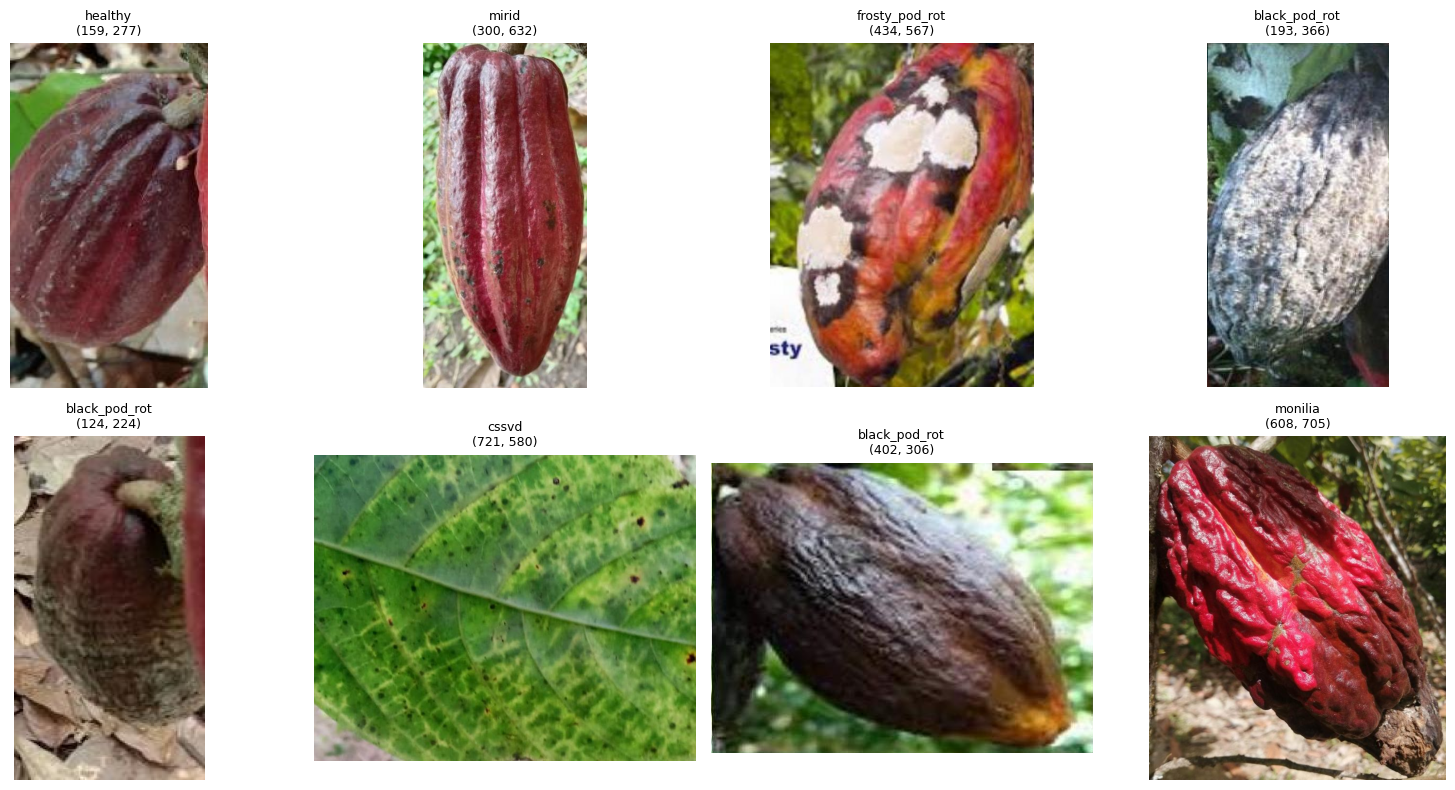

In [11]:
import matplotlib.pyplot as plt
import random

# Sample some random images across different classes
sample_size = min(8, len(image_paths))
sampled_paths = random.sample(image_paths, sample_size) if image_paths else []

if sampled_paths:
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    axes = axes.flatten()
    for i, path in enumerate(sampled_paths):
        try:
            img = Image.open(path)
            axes[i].imshow(img)
            axes[i].set_title(f"{path.parent.name}\n{img.size}", fontsize=9)
            axes[i].axis('off')
        except Exception:
            axes[i].axis('off')
    plt.tight_layout()
    plt.show()
else:
    print("No images found to display.")

### 6. Duplicates Check
We will perform a hash-based check to identify identical exact duplicate images across the dataset.

In [12]:
import hashlib

hash_dict = {}
duplicates = []

for img_path in image_paths:
    try:
        with open(img_path, 'rb') as f:
            file_hash = hashlib.md5(f.read()).hexdigest()
        if file_hash in hash_dict:
            duplicates.append((str(img_path), hash_dict[file_hash]))
        else:
            hash_dict[file_hash] = str(img_path)
    except Exception:
        pass

print(f"Total exact duplicate images found: {len(duplicates)}")
if duplicates:
    print("Sample duplicates:")
    for dup, original in duplicates[:5]:
        print(f"Duplicate: {dup} <-> Original: {original}")

Total exact duplicate images found: 1453
Sample duplicates:
Duplicate: cocoa_unified_dataset/black_pod_rot/nyarko_00011296_jpg.rf.dda4ad57ac00b550cf6667ef0a241ccc_0.jpg <-> Original: cocoa_unified_dataset/black_pod_rot/nyarko_00011296_jpg.rf.5a6cd14071a220e3ce63b702be0d5200_0.jpg
Duplicate: cocoa_unified_dataset/black_pod_rot/nyarko_0001404_jpg.rf.40646c477b76ffc37aa59d00a8425034_0.jpg <-> Original: cocoa_unified_dataset/black_pod_rot/nyarko_0001404_jpg.rf.3d59473097e49385189ce2637f1d770d_0.jpg
Duplicate: cocoa_unified_dataset/black_pod_rot/nyarko_11910_jpg.rf.734211fe62fc5e9d0810b00db901e685_0.jpg <-> Original: cocoa_unified_dataset/black_pod_rot/nyarko_11910_jpg.rf.1573cebbe0f59b30ef7efe38cc9109d2_0.jpg
Duplicate: cocoa_unified_dataset/black_pod_rot/nyarko_0001838_jpg.rf.01b799c731b62040e29ec513891b8c38_0.jpg <-> Original: cocoa_unified_dataset/black_pod_rot/nyarko_0001838_jpg.rf.3263b2b9740cfe7ee3f831f8a1f22534_0.jpg
Duplicate: cocoa_unified_dataset/black_pod_rot/nyarko_11074_jpg.rf

### 7. Splitting Strategy and Leakage Prevention

To ensure rigorous evaluation, we will:
1. **Filter Out Duplicates**: We will remove the 1,453 duplicate files identified previously. If a file is a duplicate, we only keep its first occurrence and discard others to prevent data leakage.
2. **Stratified Splitting**: Split the unique images into 70% Train, 15% Validation, and 15% Test sets.
3. **Fix Random Seed**: Set seeds for `numpy`, `random`, and `torch` to make splits and training runs reproducible.

In [13]:
import random
import numpy as np
import torch
from sklearn.model_selection import train_test_split
from pathlib import Path

# 1. Fix and document random seeds
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# 2. Re-evaluate image paths and extract classes
base_path = Path('./cocoa_unified_dataset')
all_files = list(base_path.rglob('*'))
image_extensions = {'.jpg', '.jpeg', '.png', '.bmp', '.gif', '.webp'}
image_paths = [f for f in all_files if f.is_file() and f.suffix.lower() in image_extensions]

# 3. Filter out exact duplicates to prevent leakage
import hashlib
hash_dict = {}
unique_image_paths = []

for img_path in image_paths:
    try:
        with open(img_path, 'rb') as f:
            file_hash = hashlib.md5(f.read()).hexdigest()
        if file_hash not in hash_dict:
            hash_dict[file_hash] = img_path
            unique_image_paths.append(img_path)
    except Exception:
        pass

print(f"Original Images: {len(image_paths)}")
print(f"Unique Images after removing duplicates: {len(unique_image_paths)}")

# 4. Extract labels for stratified split
labels = [p.parent.name for p in unique_image_paths]

# 5. Perform Stratified Split (70% Train, 15% Val, 15% Test)
# Split off 30% for val and test combined
train_paths, val_test_paths, train_labels, val_test_labels = train_test_split(
    unique_image_paths, labels, test_size=0.30, random_state=SEED, stratify=labels
)

# Split the remaining 30% equally into validation and test (15% / 15% of total)
val_paths, test_paths, val_labels, test_labels = train_test_split(
    val_test_paths, val_test_labels, test_size=0.50, random_state=SEED, stratify=val_test_labels
)

print(f"\nSplit results:")
print(f"Train set: {len(train_paths)} ({len(train_paths)/len(unique_image_paths)*100:.1f}%)")
print(f"Val set:   {len(val_paths)} ({len(val_paths)/len(unique_image_paths)*100:.1f}%)")
print(f"Test set:  {len(test_paths)} ({len(test_paths)/len(unique_image_paths)*100:.1f}%)")

Original Images: 19448
Unique Images after removing duplicates: 17995

Split results:
Train set: 12596 (70.0%)
Val set:   2699 (15.0%)
Test set:  2700 (15.0%)


### 8. Verification of Stratification
Let us display the class distribution across all splits to verify that the distribution ratios are maintained consistently.

In [14]:
from collections import Counter
import pandas as pd

train_counts = Counter(train_labels)
val_counts = Counter(val_labels)
test_counts = Counter(test_labels)

classes = sorted(list(train_counts.keys()))
split_data = []
for cls in classes:
    split_data.append({
        'Class': cls,
        'Train Count': train_counts[cls],
        'Val Count': val_counts[cls],
        'Test Count': test_counts[cls],
        'Total Count': train_counts[cls] + val_counts[cls] + test_counts[cls]
    })

split_df = pd.DataFrame(split_data)
display(split_df)

,Class,Train Count,Val Count,Test Count,Total Count
0,anthracnose,1585,340,339,2264
1,black_pod_rot,1898,406,407,2711
2,cssvd,2262,484,485,3231
3,frosty_pod_rot,876,188,188,1252
4,healthy,2806,601,602,4009
5,mirid,1590,340,341,2271
6,monilia,1261,271,270,1802
7,pod_borer,250,54,54,358
8,witches_broom,68,15,14,97


### 9. Custom PyTorch Dataset & Data Augmentations

We will define our PyTorch Dataset and set up data transformations.
- **Training Set**: Applying robust and realistic augmentations (rotation, horizontal & vertical flips, brightness/contrast adjustments, and resizing) to avoid overfitting.
- **Val & Test Sets**: Standard resizing and normalization only, avoiding artificial modifications.

In [15]:
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader

# Map class names to integer labels
class_to_idx = {cls_name: idx for idx, cls_name in enumerate(classes)}
idx_to_class = {idx: cls_name for cls_name, idx in class_to_idx.items()}

# Standard size for ResNet or EfficientNet networks
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32

# Define transforms
train_transforms = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_test_transforms = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

class CocoaDataset(Dataset):
    def __init__(self, paths, labels, transform=None):
        self.paths = paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img_path = self.paths[idx]
        label = self.labels[idx]
        label_idx = class_to_idx[label]

        try:
            img = Image.open(img_path).convert('RGB')
        except Exception as e:
            # Fallback to a blank image if any file fails during runtime
            img = Image.new('RGB', IMAGE_SIZE, color=0)

        if self.transform:
            img = self.transform(img)

        return img, label_idx

### 10. Building DataLoaders with Prefetching
Next, we configure PyTorch DataLoaders with multi-process workers, pinned memory, and shuffle settings to ensure highly efficient loading.

In [16]:
train_dataset = CocoaDataset(train_paths, train_labels, transform=train_transforms)
val_dataset = CocoaDataset(val_paths, val_labels, transform=val_test_transforms)
test_dataset = CocoaDataset(test_paths, test_labels, transform=val_test_transforms)

# Config physical resources for optimal loading
num_workers = 2
pin_memory = True if torch.cuda.is_available() else False

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=num_workers, pin_memory=pin_memory)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=num_workers, pin_memory=pin_memory)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=num_workers, pin_memory=pin_memory)

print(f"DataLoaders created successfully.")
print(f"Train batches: {len(train_loader)}, Val batches: {len(val_loader)}, Test batches: {len(test_loader)}")

DataLoaders created successfully.
Train batches: 394, Val batches: 85, Test batches: 85


### 11. Baseline Model Setup (ResNet-18)

We select a pre-trained **ResNet-18** as our initial baseline model because it is lightweight, fast to train, and robust.
- **Preprocessing**: Since ResNet-18 was trained on ImageNet, we use the standard ImageNet normalization (`mean=[0.485, 0.456, 0.406]`, `std=[0.229, 0.224, 0.225]`), which we already set up in our `val_test_transforms` and `train_transforms`.
- **Loss Function**: Cross-Entropy Loss to handle multi-class predictions.
- **Optimizer**: Adam with a default learning rate of `1e-4` to ensure stable initial convergence.

In [17]:
import torch
import torch.nn as nn
import torchvision.models as models

# Configure device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Load pre-trained ResNet-18
baseline_model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# Replace the classification head for 9 target classes
num_ftrs = baseline_model.fc.in_features
baseline_model.fc = nn.Linear(num_ftrs, len(classes))
baseline_model = baseline_model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(baseline_model.parameters(), lr=1e-4)

print(baseline_model)

Using device: cuda
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 131MB/s]


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

### 12. Baseline Training and Evaluation Functions
We will define training and evaluation helper functions to track loss, accuracy, and validate performance after each training cycle.

In [18]:
def train_one_epoch(model, dataloader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    correct_predictions = 0
    total_samples = 0

    for images, labels in dataloader:
        images = images.to(device)
        labels = labels.to(device)

        # Forward pass
        outputs = model(images)
        loss = criterion(outputs, labels)

        # Backward pass and optimization
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # Statistics
        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct_predictions += torch.sum(preds == labels.data)
        total_samples += labels.size(0)

    epoch_loss = running_loss / total_samples
    epoch_acc = correct_predictions.double() / total_samples
    return epoch_loss, epoch_acc.item()

def evaluate_model(model, dataloader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct_predictions = 0
    total_samples = 0

    with torch.no_grad():
        for images, labels in dataloader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            correct_predictions += torch.sum(preds == labels.data)
            total_samples += labels.size(0)

    epoch_loss = running_loss / total_samples
    epoch_acc = correct_predictions.double() / total_samples
    return epoch_loss, epoch_acc.item()

### 13. Training Loop execution
Let's train the baseline model for a few epochs (e.g., 3) to establish initial benchmark validation metrics.

In [19]:
epochs = 3
print("Starting baseline model training...")

for epoch in range(epochs):
    train_loss, train_acc = train_one_epoch(baseline_model, train_loader, criterion, optimizer, device)
    val_loss, val_acc = evaluate_model(baseline_model, val_loader, criterion, device)

    print(f"Epoch {epoch+1}/{epochs} | "
          f"Train Loss: {train_loss:.4f} - Train Acc: {train_acc*100:.2f}% | "
          f"Val Loss: {val_loss:.4f} - Val Acc: {val_acc*100:.2f}%")

Starting baseline model training...
Epoch 1/3 | Train Loss: 0.7391 - Train Acc: 73.06% | Val Loss: 0.4916 - Val Acc: 82.73%
Epoch 2/3 | Train Loss: 0.4851 - Train Acc: 82.72% | Val Loss: 0.4537 - Val Acc: 82.77%
Epoch 3/3 | Train Loss: 0.4136 - Train Acc: 84.91% | Val Loss: 0.3891 - Val Acc: 86.33%


### 14. EfficientNet-B0 Model with Transfer Learning

We will now use **EfficientNet-B0** with pre-trained ImageNet weights:
1. **Freeze the backbone**: Freeze all weights in the feature extractor backbone to retain pre-learned features.
2. **Custom Classification Head**: Replace the default classifier with our 9-class output head.
3. **Optimizer & Early Stopping**: Optimize only the newly added parameters using a learning rate of `1e-3`.

In [20]:
import torch
import torch.nn as nn
import torchvision.models as models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Training on: {device}")

# Load pretrained EfficientNet-B0
efficientnet_model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)

# Freeze feature backbone
for param in efficientnet_model.parameters():
    param.requires_grad = False

# Define a custom classification head
num_ftrs = efficientnet_model.classifier[1].in_features
efficientnet_model.classifier[1] = nn.Sequential(
    nn.Linear(num_ftrs, 256),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(256, len(classes))
)

efficientnet_model = efficientnet_model.to(device)
criterion_eff = nn.CrossEntropyLoss()
optimizer_eff = torch.optim.Adam(efficientnet_model.classifier[1].parameters(), lr=1e-3)

print(efficientnet_model)

Training on: cuda
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 155MB/s]


EfficientNet(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): SiLU(inplace=True)
    )
    (1): Sequential(
      (0): MBConv(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
            (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            (2): SiLU(inplace=True)
          )
          (1): SqueezeExcitation(
            (avgpool): AdaptiveAvgPool2d(output_size=1)
            (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
            (fc2): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
            (activation): SiLU(inplace=True)
            (scale_activation): Sigmoid()
          )
          (2): Conv2dNormActivat

### 15. Training EfficientNet-B0 with Early Stopping
We will train the frozen model for up to 8 epochs with a simple early stopping mechanism that halts training if the validation loss does not improve for 2 consecutive epochs.

In [22]:
import copy

epochs = 8
patience = 2
best_val_loss = float('inf')
patience_counter = 0
best_model_wts = copy.deepcopy(efficientnet_model.state_dict())

print("Starting EfficientNet-B0 (Feature Extraction) training...")

for epoch in range(epochs):
    train_loss, train_acc = train_one_epoch(efficientnet_model, train_loader, criterion_eff, optimizer_eff, device)
    val_loss, val_acc = evaluate_model(efficientnet_model, val_loader, criterion_eff, device)

    print(f"Epoch {epoch+1}/{epochs} | "
          f"Train Loss: {train_loss:.4f} - Train Acc: {train_acc*100:.2f}% | "
          f"Val Loss: {val_loss:.4f} - Val Acc: {val_acc*100:.2f}%")

    # Early stopping check
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_wts = copy.deepcopy(efficientnet_model.state_dict())
        patience_counter = 0
    else:
        patience_counter += 1
        if patience_counter >= patience:
            print(f"Early stopping triggered. Met patience of {patience} epochs.")
            break

# Load best model weights
efficientnet_model.load_state_dict(best_model_wts)

Starting EfficientNet-B0 (Feature Extraction) training...
Epoch 1/8 | Train Loss: 1.0446 - Train Acc: 61.46% | Val Loss: 0.7308 - Val Acc: 73.77%
Epoch 2/8 | Train Loss: 0.8312 - Train Acc: 68.88% | Val Loss: 0.6673 - Val Acc: 75.88%
Epoch 3/8 | Train Loss: 0.7665 - Train Acc: 71.66% | Val Loss: 0.6573 - Val Acc: 75.36%
Epoch 4/8 | Train Loss: 0.7274 - Train Acc: 72.55% | Val Loss: 0.6231 - Val Acc: 76.73%
Epoch 5/8 | Train Loss: 0.7036 - Train Acc: 73.83% | Val Loss: 0.5926 - Val Acc: 78.47%
Epoch 6/8 | Train Loss: 0.6966 - Train Acc: 73.81% | Val Loss: 0.5704 - Val Acc: 79.21%
Epoch 7/8 | Train Loss: 0.6548 - Train Acc: 75.60% | Val Loss: 0.5602 - Val Acc: 79.33%
Epoch 8/8 | Train Loss: 0.6472 - Train Acc: 75.50% | Val Loss: 0.5673 - Val Acc: 78.66%


<All keys matched successfully>

### 16. Comprehensive Evaluation Pipeline

We will define a reusable evaluation function to calculate the following metrics on any dataset split:
- **Accuracy**
- **Precision** (Macro-average)
- **Recall** (Macro-average)
- **F1-Score** (Macro-average)
- **Confusion Matrix**
- **Per-Class Metrics**

In [31]:
%matplotlib inline
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, classification_report
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import torch

# 1. FUNCTION TO GATHER PREDICTIONS
# This runs the models on the Validation/Test loader to extract true labels and model predictions.
def get_predictions_and_targets(model, dataloader, device):
    model.eval()  # Put model in evaluation mode
    all_preds = []
    all_targets = []

    with torch.no_grad():  # Turn off gradient calculation to save memory and speed up
        for images, labels in dataloader:
            images = images.to(device)
            outputs = model(images)  # Forward pass
            _, preds = torch.max(outputs, 1)  # Take highest logit as prediction
            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(labels.numpy())

    return np.array(all_preds), np.array(all_targets)

# 2. FUNCTION TO COMPUTE AND VISUALIZE METRICS
# Calculates Global metrics, displays a per-class report table, and plots the Confusion Matrix.
def compute_and_display_metrics(targets, preds, classes_list, title="Evaluation Summary"):
    # Calculate standard macro-averaged evaluation metrics
    acc = accuracy_score(targets, preds)
    precision, recall, f1, _ = precision_recall_fscore_support(targets, preds, average='macro', zero_division=0)

    # Display printed metrics
    print(f"=== {title} ===")
    print(f"Accuracy:  {acc*100:.2f}%")
    print(f"Precision (Macro): {precision:.4f}")
    print(f"Recall (Macro):    {recall:.4f}")
    print(f"F1-Score (Macro):  {f1:.4f}\n")

    # Generate a per-class DataFrame for clear tabular metrics
    report = classification_report(targets, preds, target_names=classes_list, output_dict=True, zero_division=0)
    report_df = pd.DataFrame(report).transpose()
    print("Per-Class Performance Table:")
    display(report_df.iloc[:len(classes_list)])

    # Generate and plot the visual Confusion Matrix heatmap
    cm = confusion_matrix(targets, preds)

    # Setup a new, distinct figure to guarantee rendering
    fig, ax = plt.subplots(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', xticklabels=classes_list, yticklabels=classes_list, cmap='Blues', ax=ax)
    ax.set_ylabel('True Label')
    ax.set_xlabel('Predicted Label')
    ax.set_title(f'Confusion Matrix - {title}')

    # Save image as backup in case notebook visualization is broken
    filename = f"confusion_matrix_{title.replace(' ', '_').replace('(', '').replace(')', '')}.png"
    plt.savefig(filename, bbox_inches='tight', dpi=150)
    print(f"Visual saved successfully to disk as: {filename}")

    plt.show()

### 17. Model Selection on Validation Set
Let's evaluate both our baseline (ResNet-18) and our transfer-learned model (EfficientNet-B0) on the validation set to compare their performances and select our final candidate.

Gathering Validation predictions for Baseline ResNet-18...
=== Baseline ResNet-18 (Val Set) ===
Accuracy:  86.33%
Precision (Macro): 0.8588
Recall (Macro):    0.8178
F1-Score (Macro):  0.8343

Per-Class Performance Table:


,precision,recall,f1-score,support
anthracnose,0.930233,0.823529,0.873635,340.0
black_pod_rot,0.754098,0.906404,0.823266,406.0
cssvd,0.870103,0.871901,0.871001,484.0
frosty_pod_rot,0.894737,0.723404,0.800000,188.0
healthy,0.857143,0.898502,0.877335,601.0
mirid,0.877493,0.905882,0.891462,340.0
monilia,0.978723,0.848708,0.909091,271.0
pod_borer,0.833333,0.648148,0.729167,54.0
witches_broom,0.733333,0.733333,0.733333,15.0


Visual saved successfully to disk as: confusion_matrix_Baseline_ResNet-18_Val_Set.png


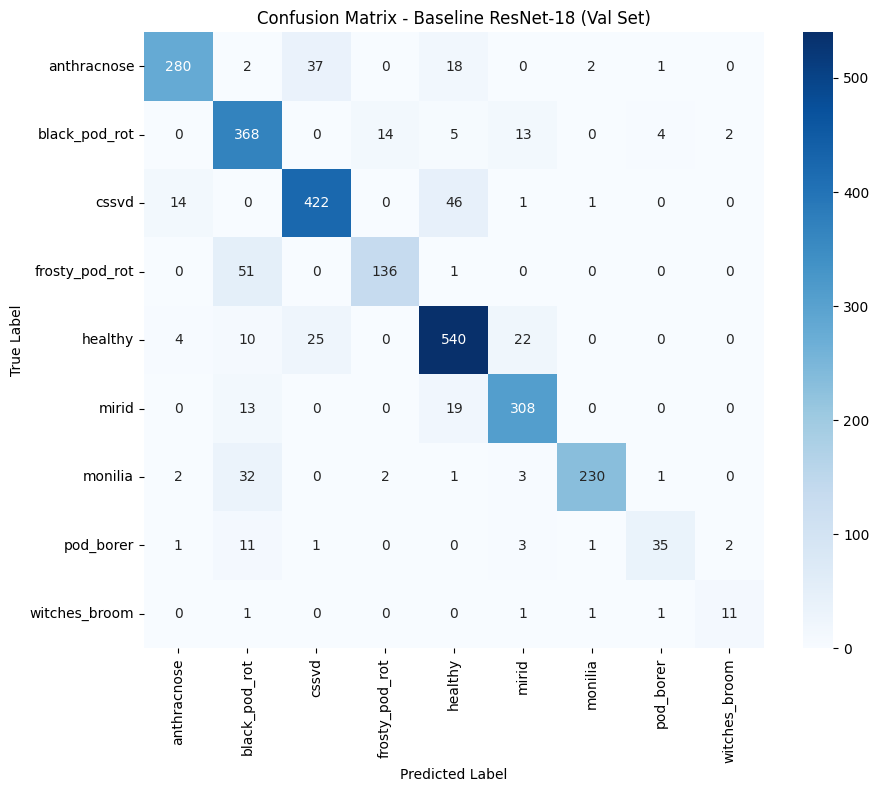


Gathering Validation predictions for EfficientNet-B0...
=== EfficientNet-B0 (Val Set) ===
Accuracy:  79.33%
Precision (Macro): 0.7514
Recall (Macro):    0.6897
F1-Score (Macro):  0.6991

Per-Class Performance Table:


,precision,recall,f1-score,support
anthracnose,0.848592,0.708824,0.772436,340.0
black_pod_rot,0.736211,0.756158,0.746051,406.0
cssvd,0.781308,0.863636,0.820412,484.0
frosty_pod_rot,0.880000,0.819149,0.848485,188.0
healthy,0.804965,0.755408,0.779399,601.0
mirid,0.793566,0.870588,0.830295,340.0
monilia,0.792880,0.904059,0.844828,271.0
pod_borer,0.625000,0.462963,0.531915,54.0
witches_broom,0.500000,0.066667,0.117647,15.0


Visual saved successfully to disk as: confusion_matrix_EfficientNet-B0_Val_Set.png


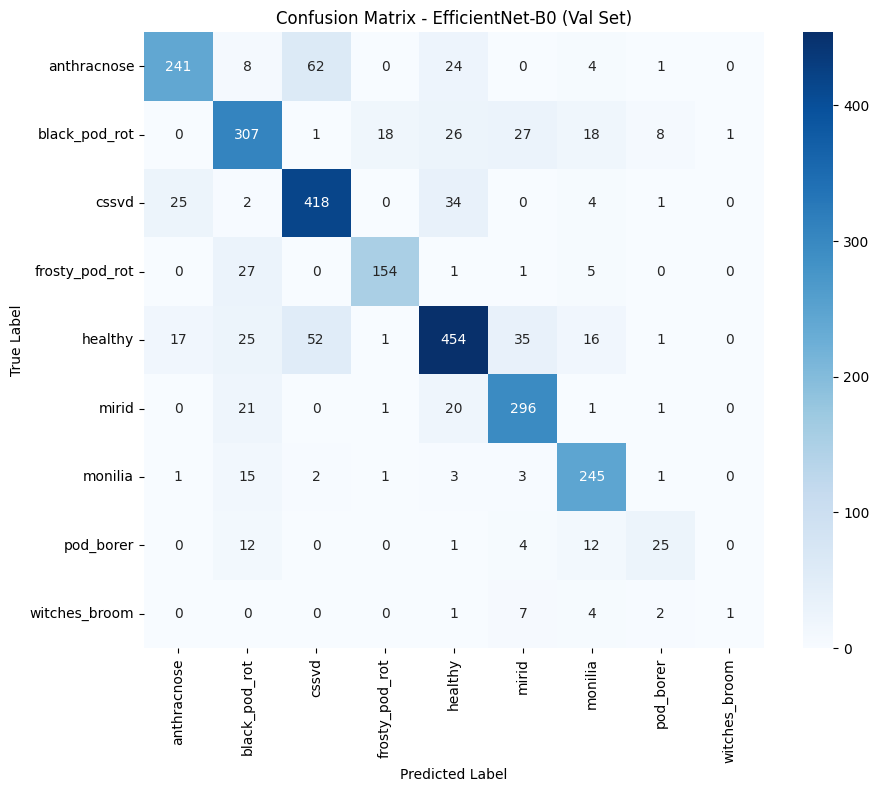

In [33]:
print("Gathering Validation predictions for Baseline ResNet-18...")
resnet_val_preds, val_targets = get_predictions_and_targets(baseline_model, val_loader, device)
compute_and_display_metrics(val_targets, resnet_val_preds, classes, title="Baseline ResNet-18 (Val Set)")

print("\nGathering Validation predictions for EfficientNet-B0...")
eff_val_preds, _ = get_predictions_and_targets(efficientnet_model, val_loader, device)
compute_and_display_metrics(val_targets, eff_val_preds, classes, title="EfficientNet-B0 (Val Set)")

### 18. Final Evaluation on Held-Out Test Set
After selecting the best-performing model based on the Validation Set, we evaluate it once on the unseen Test Set to obtain our final generalization performance report.

Evaluating Selected Final Model on the Held-Out Test Set...
=== Final Selected Model (Test Set) ===
Accuracy:  78.48%
Precision (Macro): 0.8000
Recall (Macro):    0.7315
F1-Score (Macro):  0.7467

Per-Class Performance Table:


,precision,recall,f1-score,support
anthracnose,0.839416,0.678466,0.750408,339.0
black_pod_rot,0.750000,0.737101,0.743494,407.0
cssvd,0.775472,0.847423,0.809852,485.0
frosty_pod_rot,0.857895,0.867021,0.862434,188.0
healthy,0.801085,0.735880,0.767100,602.0
mirid,0.781003,0.868035,0.822222,341.0
monilia,0.748428,0.881481,0.809524,270.0
pod_borer,0.647059,0.611111,0.628571,54.0
witches_broom,1.000000,0.357143,0.526316,14.0


Visual saved successfully to disk as: confusion_matrix_Final_Selected_Model_Test_Set.png


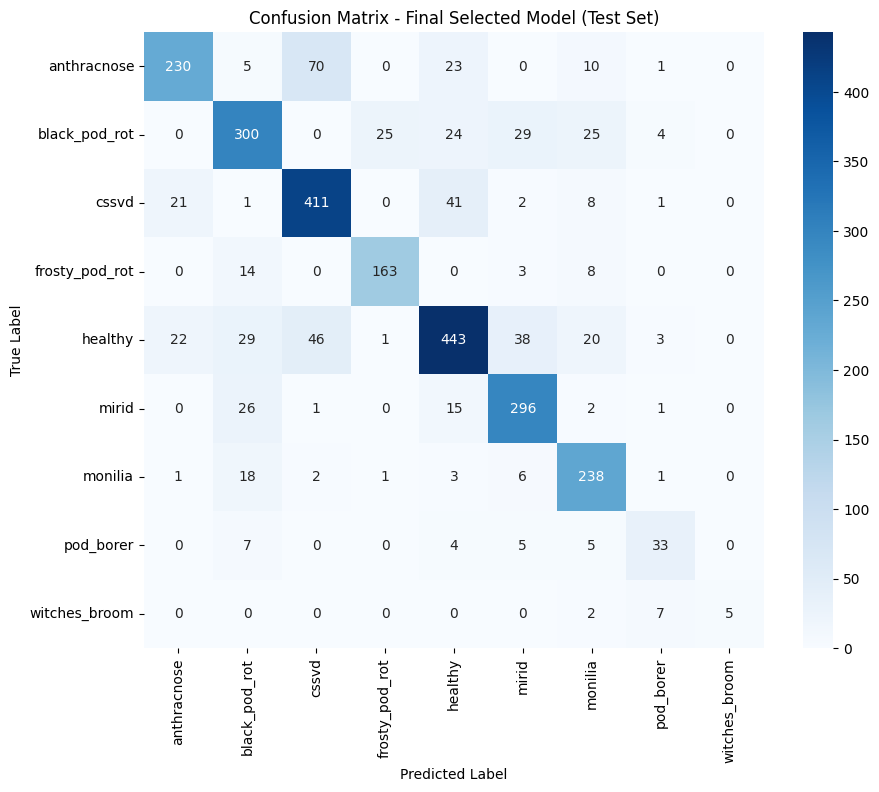

In [34]:
# Select best model and perform final test evaluation
print("Evaluating Selected Final Model on the Held-Out Test Set...")
test_preds, test_targets = get_predictions_and_targets(efficientnet_model, test_loader, device)
compute_and_display_metrics(test_targets, test_preds, classes, title="Final Selected Model (Test Set)")

### 19. Exporting the Model and Metadata
To finalize our workflow, we will save:
1. The model's weights (`best_model.pth`).
2. A comprehensive `model_metadata.json` containing class indices, image sizes, normalization configs, and evaluation metrics achieved on both validation and test sets.

In [35]:
import json

# Define the paths for exporting
model_weights_path = "best_model.pth"
metadata_path = "model_metadata.json"

# 1. Save PyTorch Model Weights
torch.save(efficientnet_model.state_dict(), model_weights_path)
print(f"Successfully saved model weights to {model_weights_path}")

# 2. Gather final evaluation metrics from our test set run
test_acc = accuracy_score(test_targets, test_preds)
test_prec, test_rec, test_f1, _ = precision_recall_fscore_support(test_targets, test_preds, average='macro', zero_division=0)

# 3. Construct detailed metadata dictionary
metadata = {
    "model_name": "EfficientNet-B0",
    "task_type": "Image Classification",
    "num_classes": len(classes),
    "classes": classes,
    "class_to_idx": class_to_idx,
    "idx_to_class": idx_to_class,
    "preprocessing_config": {
        "input_size": IMAGE_SIZE,
        "normalization_mean": [0.485, 0.456, 0.406],
        "normalization_std": [0.229, 0.224, 0.225]
    },
    "evaluation_metrics": {
        "test_accuracy": float(test_acc),
        "test_precision_macro": float(test_prec),
        "test_recall_macro": float(test_rec),
        "test_f1_macro": float(test_f1)
    }
}

# 4. Save metadata as JSON
with open(metadata_path, 'w') as f:
    json.dump(metadata, f, indent=4)

print(f"Successfully saved model metadata and configurations to {metadata_path}")

Successfully saved model weights to best_model.pth
Successfully saved model metadata and configurations to model_metadata.json


### 20. Download Model and Metadata Files
We will use `google.colab.files.download` to programmatically trigger the download of both our trained model weights and metadata files directly to your local computer.

In [36]:
from google.colab import files

# Trigger downloads for model weights and metadata json
print("Downloading best_model.pth...")
files.download('best_model.pth')

print("Downloading model_metadata.json...")
files.download('model_metadata.json')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 21. Export and Download Current Notebook (.ipynb)
We will use a secure JavaScript-based helper inside Google Colab to retrieve the current notebook's filename, save the state, and download it locally.

In [37]:
import ipykernel
from google.colab import files
import requests
from urllib.parse import unquote

# Securely fetch notebook name using internal Colab service
try:
    from google.colab import notebook
    # Try saving first
    notebook.save()
    print("Saved the current notebook state.")
except Exception:
    pass

def download_current_notebook():
    try:
        # Request notebook name from the local Colab runtime context
        notebook_json = requests.get('http://172.28.0.2:9000/api/sessions').json()
        notebook_path = notebook_json[0]['name']
        notebook_name = unquote(notebook_path)
        print(f"Notebook detected: {notebook_name}")
        files.download(notebook_name)
    except Exception as e:
        print("Could not automatically detect the notebook name. Please use 'File -> Download -> Download .ipynb' from the top menu.")

download_current_notebook()

Could not automatically detect the notebook name. Please use 'File -> Download -> Download .ipynb' from the top menu.
